# Clustering example

In [60]:
import os,sys
sys.path.append(os.path.realpath('../lib'))
import pylab as pl
import numpy as np
import ot
import FGW
from fgwclustering import FusedGromovWassersteinGraphKMeans
from graph_multimodalsentence import  graph_colors,draw_rel,draw_transp,Graph,wl_labeling,find_thresh,sp_to_adjency
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics import adjusted_mutual_info_score
from scipy.sparse.csgraph import shortest_path
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer


In [61]:
np.random.seed(12)

In [62]:
def create_graph_from_data(x,embedding):
    graphs=Graph()
    graphs.add_sentence(x,embedding)
    return graphs

In [63]:
def remove_empty_graphs(graphs,labels):
    filtered_graphs = [g for g in graphs if len(g.nodes()) > 0 and len(g.edges()) > 0]
    filtered_labels = [label for label, g in zip(labels, graphs) if len(g.nodes()) > 0 and len(g.edges()) > 0]
    return filtered_labels, filtered_graphs

In [64]:
method='shortest_path_weight'
embedding = SentenceTransformer('sentence-transformers/bert-base-nli-mean-tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7369.34it/s]


In [65]:
data = pd.read_csv('../data_with_text_tag/generated_instructions_with_intention_explanation_full_ability_gender_neutral_gemma_QA.csv')

n_sample = 15
samples_high = data[data['ability']=='High'].sample(n_sample, random_state=42)
samples_low = data[data['ability']=='Low'].sample(n_sample, random_state=42)
samples_medium = data[data['ability']=='Medium'].sample(n_sample, random_state=42)

graphs_high=[create_graph_from_data(x,embedding) for x in data[data['ability']=='High'].instruction_with_intention]
graphs_low=[create_graph_from_data(x,embedding) for x in data[data['ability']=='Low'].instruction_with_intention]
graphs_medium=[create_graph_from_data(x,embedding) for x in data[data['ability']=='Medium'].instruction_with_intention]
#remove graph with no nodes or edges
labels_high,graphs_high = remove_empty_graphs(graphs_high, data[data['ability']=='High'].instruction_with_intention.tolist())
labels_low,graphs_low = remove_empty_graphs(graphs_low, data[data['ability']=='Low'].instruction_with_intention.tolist())
labels_medium,graphs_medium = remove_empty_graphs(graphs_medium, data[data['ability']=='Medium'].instruction_with_intention.tolist())


Hard Head Nod
Talking 2
Agreeing 2
Hard Head Nod
Talking 2
Acknowledging
Hard Head Nod
Talking 2
Acknowledging
Hard Head Nod
Talking 2
Acknowledging
Hard Head Nod
Talking 2
Lengthy Head Nod
Hard Head Nod
Talking 2
Acknowledging
Talking 2
Hard Head Nod
Pointing
Hard Head Nod
Talking 2
Acknowledging
Hard Head Nod
Talking 2
Pointing
Talking 2
Hard Head Nod
Pointing
Hard Head Nod
Talking 2
Acknowledging
Talking 2
Hard Head Nod
Acknowledging
Talking 2
Hard Head Nod
Agreeing 2
Hard Head Nod
Talking 2
Agreeing 2
Talking 2
Hard Head Nod
Acknowledging
Talking 2
Hard Head Nod
Acknowledging
Talking 2
Hard Head Nod
Talking 2
Hard Head Nod
Pointing
Hard Head Nod
Talking 2
Talking 2
Hard Head Nod
Acknowledging
Hard Head Nod
Talking 2
Agreeing 2
Hard Head Nod
Talking 2
Acknowledging
Hard Head Nod
Talking 2
Pointing
Hard Head Nod
Talking 2
Pointing
Hard Head Nod
Talking 2
Lengthy Head Nod
Hard Head Nod
Talking 2
Acknowledging
Talking 2
Hard Head Nod
Acknowledging
Talking 2
Hard Head Nod
Acknowledging


In [66]:

X = graphs_high + graphs_low + graphs_medium
y = ['High']*len(graphs_high) + ['Low']*len(graphs_low) + ['Medium']*len(graphs_medium)

In [67]:
len(X)

1464

In [68]:
# Precompute all the shortest path distances
for x in X:
    C=x.distance_matrix(method='shortest_path',force_recompute=True)

In [69]:
alpha=0.14 # here the structure is more driving the classes
fgw_kmeans=FusedGromovWassersteinGraphKMeans(N=15,n_clusters=3,max_iter=15
                                             ,max_iter_barycenter=60,n_init=2
                                             ,metric_params={"alpha":alpha},verbose=1)

In [70]:
fgw_kmeans.fit(np.array(X))

Init 1
 Inertia : 62.573   -->   Inertia : 35.513   -->   Inertia : 32.393   -->   Inertia : 31.739   -->   Inertia : 32.027   -->   Inertia : 31.790   -->   Inertia : 30.469   -->   Inertia : 29.879   -->   Inertia : 29.959   -->   Inertia : 29.510   -->   Inertia : 29.417   -->   Inertia : 29.392   -->   Inertia : 29.335   -->   Inertia : 29.701   -->   Inertia : 29.313   -->  


In [71]:
adjusted_mutual_info_score(y,fgw_kmeans.labels_)

0.8942977240072231

In [72]:
df = pd.DataFrame({'instruction_with_intention': labels_high + labels_low + labels_medium, 'predicted_category': fgw_kmeans.labels_, 'true_category': y})

<Axes: xlabel='predicted_category', ylabel='Count'>

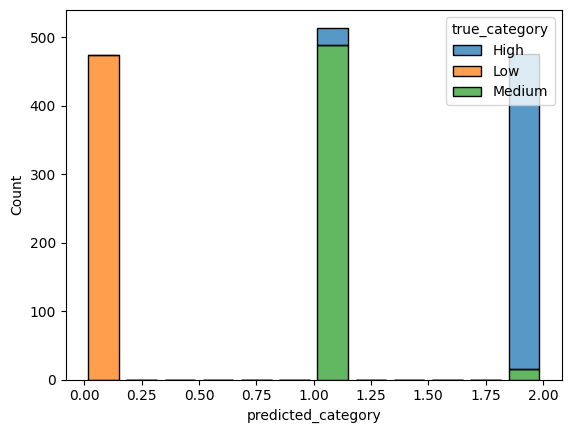

In [73]:
sns.histplot(data=df, x='predicted_category', hue='true_category', multiple='stack', shrink=0.8)

In [74]:
labels = ['Low', 'Medium', 'High']
df['predicted_label'] = df['predicted_category'].map({i: label for i, label in enumerate(labels)})
df.to_csv('../data_with_text_tag/generated_instructions_with_intention_explanation_full_ability_gender_neutral_gemma_QA_ratedbyFGW.csv', index=False)